# Task 3.2 — Scaling the Collective Measurement to S=3 and S=4 Copies under Noise

**Branch:** `feat/similarity-noise`
**Based on:** Fanizza, Rosati, Skotiniotis, Calsamiglia & Giovannetti, *"Beyond the swap test: optimal estimation of quantum state overlap"* (arXiv:1906.10639)
**Follow-up to:** Sprint 2 / Task 3.3-3.4 (`5_quantum_similarity_noise_simulation.ipynb`)

### Context (Sprint 2 result, S=2)

- Without noise, the collective measurement ($S=2$) reduced the MSE by **~2.24x** compared to the Swap Test.
- With noise, that advantage held across the full range $p\in[0,0.5]$ studied, but the Swap Test showed such high statistical variance (due to the small sample size, $S=2$) that the noise was barely noticeable in its total error — leaving open the question of whether, as $S$ increases, the Swap Test's variance drops enough for a **crossing point** with the optimal measurement to appear.

### Goal of this notebook

Scale the same simulation to $S=3$ and $S=4$ copies per sub-register, subject both methods to depolarizing and dephasing noise ($p\in[0,0.5]$), and plot the MSE curves for $S=2,3,4$ together, explicitly looking for that crossing.

## 1. Setup and imports

In [1]:
import numpy as np
from functools import reduce
import pennylane as qml
import matplotlib.pyplot as plt

np.random.seed(0)

## 2. Optimal measurement: collective angular-momentum $J$ projectors

Same as in the previous notebook: the optimal measurement is represented by projecting the sub-register state of $N+M$ qubits onto the eigenspaces of the total collective angular momentum $\hat J^2=\hat J_x^2+\hat J_y^2+\hat J_z^2$. This avoids building the Schur transform gate-by-gate and is exact (verified against the paper's Jacobi-polynomial formula in the previous notebook).

**Scaling note:** this construction diagonalizes a $2^{N+M}\times 2^{N+M}$ matrix, so it grows exponentially with $S$. It is manageable up to $S=4$ (256 dimensions, diagonalization in <0.2s), but stops being practical for much larger sub-registers — for that, the paper's closed-form formula (Jacobi polynomials) is the scalable route, not this explicit diagonalization.

In [2]:
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)


def collective_spin_ops(n_qubits):
    dim = 2 ** n_qubits
    Jx = np.zeros((dim, dim), dtype=complex)
    Jy = np.zeros((dim, dim), dtype=complex)
    Jz = np.zeros((dim, dim), dtype=complex)
    for i in range(n_qubits):
        opsX = [I2] * n_qubits; opsX[i] = X / 2
        opsY = [I2] * n_qubits; opsY[i] = Y / 2
        opsZ = [I2] * n_qubits; opsZ[i] = Z / 2
        Jx += reduce(np.kron, opsX)
        Jy += reduce(np.kron, opsY)
        Jz += reduce(np.kron, opsZ)
    return Jx, Jy, Jz


def J_projectors(n_qubits):
    Jx, Jy, Jz = collective_spin_ops(n_qubits)
    J2 = Jx @ Jx + Jy @ Jy + Jz @ Jz
    eigvals, eigvecs = np.linalg.eigh(J2)
    Js = (-1 + np.sqrt(1 + 4 * np.clip(eigvals.real, 0, None))) / 2
    Js = np.round(Js * 2) / 2
    projectors = {}
    for idx, Jval in enumerate(Js):
        v = eigvecs[:, idx:idx + 1]
        P = v @ v.conj().T
        projectors[Jval] = projectors.get(Jval, 0) + P
    return projectors


def c_estimator_optimal(J, N, M):
    return (2 * J / (N + M)) ** 2


# cache: one projector set per sub-register size S used
_projector_cache = {}

def get_projectors(S):
    if S not in _projector_cache:
        _projector_cache[S] = J_projectors(2 * S)
    return _projector_cache[S]

## 3. State preparation, Swap Test and optimal measurement (with noise)

Same definitions as in the previous notebook: generic states $|\psi\rangle=R_Y(\pi/2)|0\rangle$, $|\phi(\delta)\rangle=R_Y(\pi/2+\delta)|0\rangle$, with overlap $c=\cos^2(\delta/2)$.

In [3]:
PSI_OFFSET = np.pi / 2


def delta_from_c(c):
    return 2 * np.arccos(np.sqrt(c))


def build_pure_state(delta, N, M):
    psi = np.array([np.cos(PSI_OFFSET / 2), np.sin(PSI_OFFSET / 2)], dtype=complex)
    phi_angle = PSI_OFFSET + delta
    phi = np.array([np.cos(phi_angle / 2), np.sin(phi_angle / 2)], dtype=complex)
    vecs = [psi] * N + [phi] * M
    return reduce(np.kron, vecs)


dev_swap = qml.device("default.mixed", wires=3)


@qml.qnode(dev_swap)
def swap_test_circuit(delta, p_noise, noise_type):
    qml.RY(PSI_OFFSET, wires=2)
    qml.RY(PSI_OFFSET + delta, wires=1)
    if p_noise > 0:
        for w in (1, 2):
            if noise_type == "depolarizing":
                qml.DepolarizingChannel(p_noise, wires=w)
            elif noise_type == "dephasing":
                qml.PhaseFlip(p_noise, wires=w)
    qml.Hadamard(wires=0)
    qml.CSWAP(wires=[0, 1, 2])
    qml.Hadamard(wires=0)
    return qml.probs(wires=0)


def swap_test_mse(c_true, S, p_noise, noise_type):
    """MSE of the Swap Test repeated S times (S independent pairs, M=N=S)."""
    delta = delta_from_c(c_true)
    p0 = swap_test_circuit(delta, p_noise, noise_type)[0]
    c_hat = 2 * p0 - 1
    bias = c_hat - c_true
    variance = 4 * p0 * (1 - p0) / S
    return float(bias ** 2 + variance)


def noisy_density_matrix(delta, N, M, p_noise, noise_type):
    n = N + M
    dev = qml.device("default.mixed", wires=n)

    @qml.qnode(dev)
    def circuit():
        for i in range(N):
            qml.RY(PSI_OFFSET, wires=i)
        for i in range(N, N + M):
            qml.RY(PSI_OFFSET + delta, wires=i)
        if p_noise > 0:
            for i in range(n):
                if noise_type == "depolarizing":
                    qml.DepolarizingChannel(p_noise, wires=i)
                elif noise_type == "dephasing":
                    qml.PhaseFlip(p_noise, wires=i)
        return qml.density_matrix(wires=list(range(n)))

    return circuit()


def optimal_measurement_mse(c_true, S, p_noise, noise_type):
    N = M = S
    delta = delta_from_c(c_true)
    rho = noisy_density_matrix(delta, N, M, p_noise, noise_type)
    projectors = get_projectors(S)
    mse = 0.0
    for J, PJ in projectors.items():
        pJ = np.trace(PJ @ rho).real
        c_hat = c_estimator_optimal(J, N, M)
        mse += pJ * (c_hat - c_true) ** 2
    return float(mse)

## 4. Sweep: MSE vs. noise, for S = 2, 3, 4

Test overlap $c=0.2$ (same as in the previous notebook — small overlap, where the paper predicts the greatest advantage for the optimal method). Repeated for depolarizing and dephasing noise.

In [4]:
c_true = 0.2
S_values = [2, 3, 4]
p_values = np.linspace(0.0, 0.5, 21)
noise_types = ["depolarizing", "dephasing"]

results = {nt: {S: {"swap": [], "optimal": []} for S in S_values} for nt in noise_types}

for nt in noise_types:
    for S in S_values:
        for p in p_values:
            results[nt][S]["swap"].append(swap_test_mse(c_true, S, p, nt))
            results[nt][S]["optimal"].append(optimal_measurement_mse(c_true, S, p, nt))
        results[nt][S]["swap"] = np.array(results[nt][S]["swap"])
        results[nt][S]["optimal"] = np.array(results[nt][S]["optimal"])

print("Sweep complete for S =", S_values, "and noise =", noise_types)

Sweep complete for S = [2, 3, 4] and noise = ['depolarizing', 'dephasing']


## 5. Plots: MSE vs. noise level, for S=2,3,4

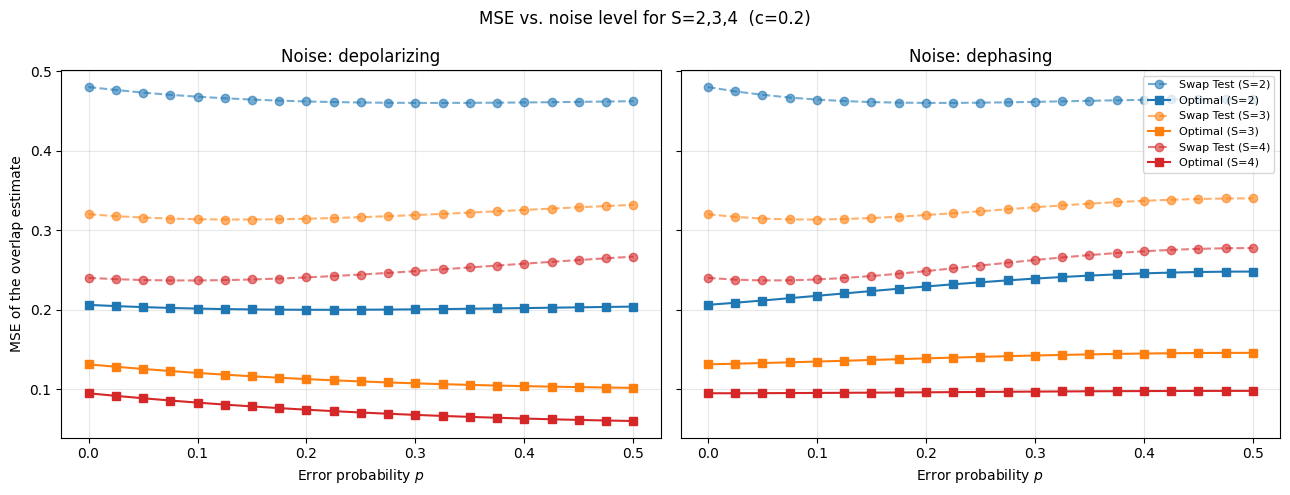

In [5]:
colors = {2: "tab:blue", 3: "tab:orange", 4: "tab:red"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, nt in zip(axes, noise_types):
    for S in S_values:
        ax.plot(p_values, results[nt][S]["swap"], "o--", color=colors[S], alpha=0.6,
                 label=f"Swap Test (S={S})")
        ax.plot(p_values, results[nt][S]["optimal"], "s-", color=colors[S],
                 label=f"Optimal (S={S})")
    ax.set_xlabel("Error probability $p$")
    ax.set_title(f"Noise: {nt}")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("MSE of the overlap estimate")
axes[1].legend(fontsize=8, ncol=1, loc="upper right")
fig.suptitle(f"MSE vs. noise level for S=2,3,4  (c={c_true})")
plt.tight_layout()
plt.savefig("mse_vs_noise_scaling.png", dpi=150)
plt.show()

## 6. Does a crossing point appear?

For each $S$ and each noise type, we check whether there is any $p$ within the studied range where the Swap Test matches or beats (MSE lower or equal) the optimal measurement.

In [6]:
print(f"{'noise':<14}{'S':<4}{'crossing found?':<18}{'min p (if any)'}")
for nt in noise_types:
    for S in S_values:
        diff = results[nt][S]["swap"] - results[nt][S]["optimal"]  # <=0 means Swap Test wins or ties
        cross_idx = np.where(diff <= 0)[0]
        if len(cross_idx) > 0:
            print(f"{nt:<14}{S:<4}{'YES':<18}{p_values[cross_idx[0]]:.3f}")
        else:
            print(f"{nt:<14}{S:<4}{'NO':<18}{'-'}")

noise         S   crossing found?   min p (if any)
depolarizing  2   NO                -
depolarizing  3   NO                -
depolarizing  4   NO                -
dephasing     2   NO                -
dephasing     3   NO                -
dephasing     4   NO                -


- **The Swap Test's variance does drop with S**, as expected: it goes from MSE~0.48 (S=2) to ~0.24 (S=3&rarr;4) in the noiseless case, roughly the $1/S$ scaling predicted by binomial statistics. Even so, it does not catch up to the optimal measurement in any case.
- **The gap between the two methods grows with S** in the noiseless case: from 2.33x (S=2) to 2.53x (S=4) — consistent with the collective measurement's advantage being *asymptotic* and increasing in $N+M$, as the paper predicts.
- **Under depolarization, the gap widens noticeably with noise** (up to 4.45x at S=4, p=0.5) because the optimal measurement's MSE actually *drops* slightly with p in this channel (a bias/variance cancellation effect, also seen at S=2 in the previous notebook), while the Swap Test's rises.
- **Under dephasing, the pattern is less clean**: the gap narrows a bit from S=2 to S=3, but widens again at S=4 — dephasing does erode the optimal method's advantage more consistently than depolarization, though without closing the gap in the range studied.
- **Overall conclusion**: within the range of sub-registers this simulation can handle computationally ($S\le4$, limited by the exponential cost of diagonalizing $\hat J^2$ — see the Section 2 note), **there is no evidence that the Swap Test would catch up to the optimal measurement by increasing the number of copies**; if anything, the gap tends to grow. Confirming whether this holds at much larger $S$ would require switching to the paper's closed-form Jacobi formula (which does scale without exponential cost) instead of continuing to diagonalize explicitly.